# Experiment Log — Clustering

## Eksperimen 1: Perbandingan Algoritma

- **Tujuan:** Membandingkan performa KMeans, MeanShift, dan DBSCAN.

- **Dataset:**

- **Fitur yang digunakan:**

- **Preprocessing:** scalling

- **Parameter model:**

| Algoritma | Jumlah Cluster | Noise | Silhouette Score | Waktu (detik) |
| --------- | -------------- | ----- | ---------------- | ------------- |
|  KMeans   |        5       |       |0.3230470361871365|               |
|  DBSCAN   |        17      |   49  |    0.13677       |               |
|           |                |       |                  |               |
|           |                |       |                  |               |

## **Observasi:**

## **Kesimpulan:**

## Eksperimen 2: Kombinasi Fitur

- **Algoritma terpilih:**

- **Tujuan:** Menguji hasil clustering terhadap beberapa kombinasi fitur.

| Percobaan | Fitur | Silhouette Score | ARI terhadap Baseline |
| --------- | ----- | ---------------- | --------------------- |
|           |       |                  |                       |
|           |       |                  |                       |
|           |       |                  |                       |

## **Observasi:**

## **Kesimpulan:**

- Algoritma kandidat:
- Konfigurasi kandidat:
- Alasan pemilihan:
- Keterbatasan:
- Eksperimen lanjutan:


In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('scaler_X.csv')

In [13]:
df = df.drop(columns='Unnamed: 0') 

In [14]:
df

,age,annual_income,health_status,number_of_dependents
0,0.917541,0.876889,-1.130391,1.579482
1,-1.406595,-0.820312,1.046286,-0.255420
2,0.401066,-0.871743,1.046286,-1.172872
3,0.401066,-0.614591,1.046286,-1.172872
4,0.831461,1.776920,-1.130391,1.579482
...,...,...,...,...
9959,-1.234437,-0.614591,-1.130391,-1.172872
9960,-0.804041,-0.460300,1.046286,-0.255420
9961,-1.406595,0.182579,-0.042052,0.662031
9962,1.950490,0.054003,-0.042052,0.662031


In [15]:
# Algoritma KMeans
from sklearn.cluster import KMeans

In [16]:
# Harus konsisten dalam menetapkan random statenya
km = KMeans(n_clusters=5, n_init=10, random_state=42)  

km.fit(df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 4)","[[ 1.

In [18]:
km.inertia_ # semakin kecil inertia maka semakin bagus karena semakin dekat dengan centroidnya tapi semakin kecil tapi belum tentu semakin bagus

15101.694534723983

In [19]:
# wcss/inertia
# elbow method

inertia = []

for i in range(2, 9):
    km = KMeans(n_clusters=i, n_init=10, random_state=42)  

    km.fit(df)
    inertia.append(km.inertia_)
    

In [20]:
inertia

[27990.122787691213,
 22173.5506014632,
 18300.52335354609,
 15101.694534723983,
 12793.093398376019,
 11377.136040891537,
 10320.519365795708]

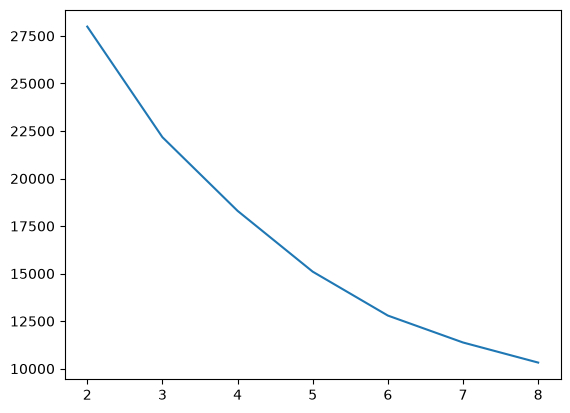

In [21]:
# visualisasi inertia

import matplotlib.pyplot as plt

plt.plot(range(2,9), inertia)

In [22]:
df

,age,annual_income,health_status,number_of_dependents
0,0.917541,0.876889,-1.130391,1.579482
1,-1.406595,-0.820312,1.046286,-0.255420
2,0.401066,-0.871743,1.046286,-1.172872
3,0.401066,-0.614591,1.046286,-1.172872
4,0.831461,1.776920,-1.130391,1.579482
...,...,...,...,...
9959,-1.234437,-0.614591,-1.130391,-1.172872
9960,-0.804041,-0.460300,1.046286,-0.255420
9961,-1.406595,0.182579,-0.042052,0.662031
9962,1.950490,0.054003,-0.042052,0.662031


In [25]:
# Hasil Prediksi Clustering
km = KMeans(n_clusters=5, n_init=10, random_state=42)  

km_cluster = km.fit_predict(df)

In [26]:
# silhoutte score
from sklearn.metrics import silhouette_score
silhouette_score(df, km_cluster) # 

0.3230470361871365

In [28]:
# Algoritma Meanshift
from sklearn.cluster import MeanShift

In [30]:
ms = MeanShift(bandwidth=.5)

ms_cluster = ms.fit_predict(df)

In [40]:
silhouette_score(df, ms_cluster)

0.36008709137197764

In [38]:
# Algoritma DBSCAN
from sklearn.cluster import DBSCAN

db = DBSCAN()

db_cluster = db.fit_predict(df)


In [39]:
set(db_cluster)

{np.int64(-1),
 np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17)}

In [41]:
silhouette_score(df, db_cluster)


0.13677105941089213

In [37]:
# menghitung data outliers
len(db_cluster[db_cluster == -1])

49

In [43]:
clustered_df = pd.concat([df,pd.Series(km_cluster)], axis=1) # convert array menjadi dataFrame/data series

In [44]:
clustered_df

,age,annual_income,health_status,number_of_dependents,0
0,0.917541,0.876889,-1.130391,1.579482,2
1,-1.406595,-0.820312,1.046286,-0.255420,4
2,0.401066,-0.871743,1.046286,-1.172872,4
3,0.401066,-0.614591,1.046286,-1.172872,4
4,0.831461,1.776920,-1.130391,1.579482,3
...,...,...,...,...,...
9959,-1.234437,-0.614591,-1.130391,-1.172872,1
9960,-0.804041,-0.460300,1.046286,-0.255420,4
9961,-1.406595,0.182579,-0.042052,0.662031,2
9962,1.950490,0.054003,-0.042052,0.662031,0


In [46]:
clustered_df.columns

Index(['age', 'annual_income', 'health_status', 'number_of_dependents', 0], dtype='object')

In [56]:
clustered_df.groupby(0, as_index=False)[['age', 'annual_income', 'health_status', 'number_of_dependents']].mean()

,0,age,annual_income,health_status,number_of_dependents
0,0,1.440151,-0.532749,0.153745,-0.446634
1,1,-0.809149,-0.654433,-0.972846,-1.062121
2,2,-0.087679,0.117846,-1.008767,0.838204
3,3,0.597215,1.502013,0.480372,0.910304
4,4,-0.585388,-0.425910,0.998289,-0.249887


In [48]:
from sklearn.decomposition import PCA

In [49]:
pca = PCA(n_components=2)

pca_df  = pca.fit_transform(df)

In [52]:
pca.explained_variance_ratio_
pca_df

array([[ 1.75237795, -1.40115101],
       [-1.1241237 ,  1.06883864],
       [-0.92458041,  1.37103922],
       ...,
       [-0.1054778 , -0.29176914],
       [ 1.30456178,  0.01862524],
       [ 0.22894846,  0.75840093]], shape=(9964, 2))

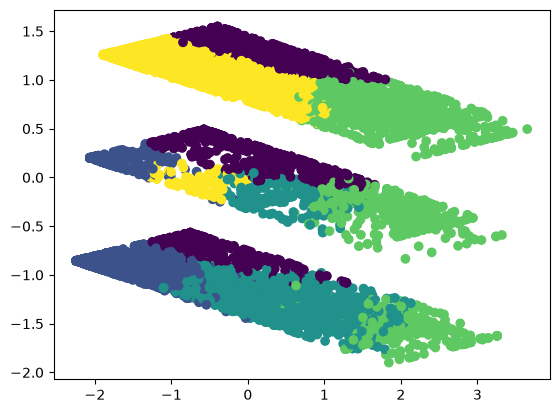

In [54]:
plt.scatter(pca_df[:,0], pca_df[:,1], c=clustered_df[0])

## Classification

In [58]:
df = pd.read_csv('adult.csv')

In [64]:
# cek informasi data

df.info
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

In [65]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='str')

In [ ]:
# Selection Columns yang akan dipakai yang mempengaruhi pendapatan(income)
feature = ['workclass', 'age', 'education-num', 'marital-status', 'occupation', 'hours-per-week', 'native-country']

In [67]:
X = df[feature]
y = df['income']

In [68]:
X

,workclass,age,education-num,marital-status,occupation,hours-per-week,native-country
0,State-gov,39,13,Never-married,Adm-clerical,40,United-States
1,Self-emp-not-inc,50,13,Married-civ-spouse,Exec-managerial,13,United-States
2,Private,38,9,Divorced,Handlers-cleaners,40,United-States
3,Private,53,7,Married-civ-spouse,Handlers-cleaners,40,United-States
4,Private,28,13,Married-civ-spouse,Prof-specialty,40,Cuba
...,...,...,...,...,...,...,...
48837,Private,39,13,Divorced,Prof-specialty,36,United-States
48838,Never-worked,64,9,Widowed,Never-worked,40,United-States
48839,Private,38,13,Married-civ-spouse,Prof-specialty,50,United-States
48840,Private,44,13,Divorced,Adm-clerical,40,United-States


In [70]:
# Melihat unique value
#X['workclass'].unique()
X['native-country'].unique()

<StringArray>
[             'United-States',                       'Cuba',
                    'Jamaica',                      'India',
                          '?',                     'Mexico',
                      'South',                'Puerto-Rico',
                   'Honduras',                    'England',
                     'Canada',                    'Germany',
                       'Iran',                'Philippines',
                      'Italy',                     'Poland',
                   'Columbia',                   'Cambodia',
                   'Thailand',                    'Ecuador',
                       'Laos',                     'Taiwan',
                      'Haiti',                   'Portugal',
         'Dominican-Republic',                'El-Salvador',
                     'France',                  'Guatemala',
                      'China',                      'Japan',
                 'Yugoslavia',                       'Peru',
 'Outlying

In [71]:
X[X['native-country'] == '?']

,workclass,age,education-num,marital-status,occupation,hours-per-week,native-country
14,Private,40,11,Married-civ-spouse,Craft-repair,40,?
38,Private,31,10,Married-civ-spouse,Sales,38,?
51,Private,18,9,Never-married,Other-service,30,?
61,Never-worked,32,4,Married-spouse-absent,Never-worked,40,?
93,Private,30,9,Married-civ-spouse,Sales,35,?
...,...,...,...,...,...,...,...
48245,Private,46,7,Married-civ-spouse,Other-service,40,?
48272,Private,24,10,Never-married,Other-service,24,?
48604,State-gov,24,13,Never-married,Transport-moving,40,?
48651,Private,34,14,Never-married,Prof-specialty,45,?


In [72]:
len(X)

48842

In [ ]:
# Skenario jadi data native-country=? dihapus